<a href="https://colab.research.google.com/github/ninkkka/data_analysis_labs/blob/main/lab2/lab2_k_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №2**

## **Кластерный анализ методом k-средних**

**Тема**: Сегментация потребителей леденцов по мотивам потребления

**Цель**: Сегментировать потребителей леденцов по мотивам их потребления для последующего формирования маркетинговых стратегий

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

In [ ]:
df = pd.read_csv('Леденцы.dat', sep=';')

df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Выделим из исходной таблицы признаки, по которым будет производиться кластеризация. Это необходимо для того, чтобы алгоритм учитывал только характеристики покупателей, важные для исследования

In [ ]:
feature_cols = [
    'V1', 'V2', 'V3', 'V4', 'V5', 'V6',
    'V7', 'V8', 'V9', 'V10', 'V11'
]

X = df[feature_cols].values

Для алгоритма k-means необходимо заранее знать кол-во кластеров. Чтобы его определить, можно использовать метод локтя. При запуске с разным количеством кластеров рассчитывается Inertia - сумма квадратов расстояний объектов до центров своих кластеров. Далее строится график и ищется точка, после которой снижение Inertia заметно замедляется. Именно это помогает выбрать разумное кол-во кластеров

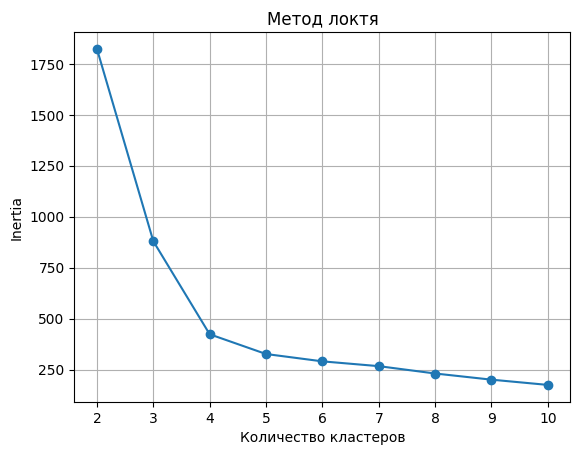

In [ ]:
inertias = []

for k in range(2, 11):
    model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
    )

    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.grid()
plt.show()

Для дополниетльного обоснования количества кластеров рассчитаны три мтерики качества при различных значениях k от 2 до 10:
- **коэффициент силуэта** - оценивает компактность кластеров и степень их разделенности (чем выше значение, тем лучше)
- **индекс Дэвиса-Болдуина** - характеризует соотношение внутрикластерного разброса и расстояний между кластерами (чем ниже значение, тем лучше)
- **индекс Калинского-Харабаша** - оценивает соотношение межкластерного и внутрикластерного разброса (чем выше значение, тем лучше)

Использование нескольких метрик позволяет оценить результаты с разных сторон и выбрать наиболее обоснованное кол-во кластеров

In [ ]:
rows = []

for k in range(2, 11):
    model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
    )

    labels = model.fit_predict(X)

    rows.append({
        'K': k,
        'silhouette': silhouette_score(X, labels),
        'davies_bouldin': davies_bouldin_score(X, labels),
        'calinski_harabasz': calinski_harabasz_score(X, labels)
    })

results = pd.DataFrame(rows)
results.round(3)

,K,silhouette,davies_bouldin,calinski_harabasz
0,2,0.455,0.930,246.334
1,3,0.614,0.784,434.178
2,4,0.727,0.433,720.103
3,5,0.702,0.634,723.115
4,6,0.704,0.627,656.670
5,7,0.626,0.816,598.574
6,8,0.631,0.790,598.865
7,9,0.657,0.798,607.428
8,10,0.672,0.738,623.263


**Вывод по выбору количества кластеров**

Наилучшее значение коэффициента силуэта (0,727) и минимальное значение индекса Дэвиса–Болдуина (0,433) достигаются при k = 4

Индекс Калинского–Харабаша принимает максимальное значение при k = 5 (723,115), однако при k = 4 его значение составляет 720,103, что лишь незначительно ниже

Таким образом, по совокупности метрик для дальнейшего анализа выбрано **4 кластера**. Такое разбиение обеспечивает хорошую компактность и разделённость групп при сохранении возможности их содержательной интерпретации

На основании проведённого анализа выбрано количество кластеров k = 4

Обучим модель K-means на исходных 11 признаках. Алгоритм последовательно распределяет объекты по ближайшим центроидам и пересчитывает координаты центров до достижения сходимости

Для воспроизводимости результатов зафиксируем random_state=42, а параметр n_init=10 позволит выбрать лучший результат из десяти запусков с разными начальными центрами

После обучения каждому покупателю присваивается номер кластера. Рассчитаем численность полученных групп

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['cluster'] = kmeans.fit_predict(X)

df['cluster'].value_counts().sort_index()

,count
cluster,
0,108
1,61
2,110
3,59


Все четыре кластера содержат достаточно большое количество наблюдений. Наиболее многочисленным является кластер 2, а наименее многочисленным — кластер 3

Для определения характерных особенностей каждой группы рассчитаем средние значения признаков V1–V11 внутри кластеров

Полученные значения соответствуют координатам центроидов K-means и позволяют определить наиболее выраженные мотивы потребления

На основании преобладающих признаков выделим содержательные типы покупателей

In [ ]:
cluster_means = df.groupby('cluster')[feature_cols].mean()

cluster_means.round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


Анализ средних значений признаков позволил выделить четыре группы потребителей:

- Кластер 0 — лечебный мотив. Наиболее высокие оценки наблюдаются по признакам V9–V11 (4,81–4,95), связанным с лечебными свойствами леденцов
- Кластер 1 — сладкий вкус. Преобладают признаки V5 и V6, средние оценки которых составляют 4,85
- Кластер 2 — свежесть и уверенность. Высокие значения признаков V1–V4 (4,68–4,85) свидетельствуют о выраженности мотивов свежести дыхания и уверенности
- Кластер 3 — концентрация и отвлечение. Признаки V7 и V8 имеют средние значения 4,92 и характеризуют основной мотив данной группы

Таким образом, выделенные кластеры различаются преобладающими мотивами потребления, что позволяет использовать их для сегментации покупателей

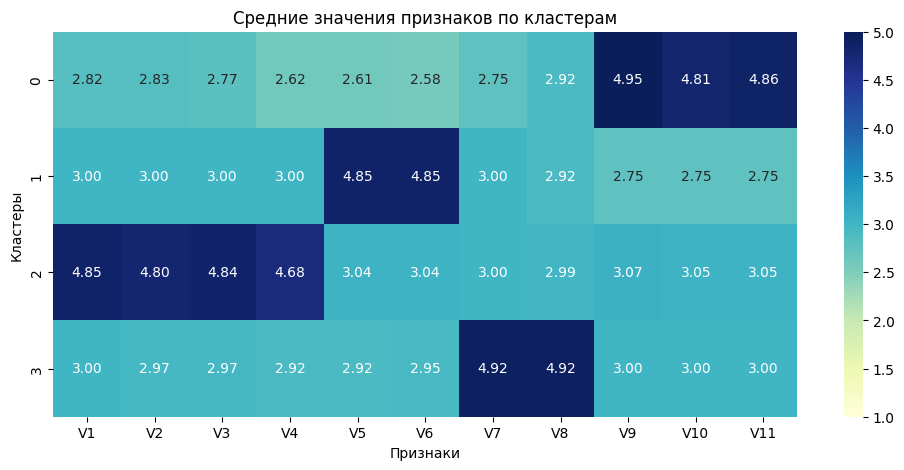

In [ ]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=1,
    vmax=5
)

plt.title('Средние значения признаков по кластерам')
plt.xlabel('Признаки')
plt.ylabel('Кластеры')
plt.show()

**Визуализация кластеров методом главных компонент (PCA)**

Поскольку исходные данные содержат 11 признаков, непосредственно представить их на двумерном графике затруднительно

Для снижения размерности используем метод главных компонент (PCA), который преобразует исходные признаки в две новые координаты, сохраняя максимально возможную долю дисперсии при таком преобразовании

Полученные координаты используем для визуализации ранее сформированных кластеров K-means. При этом сама кластеризация выполняется в исходном пространстве 11 признаков

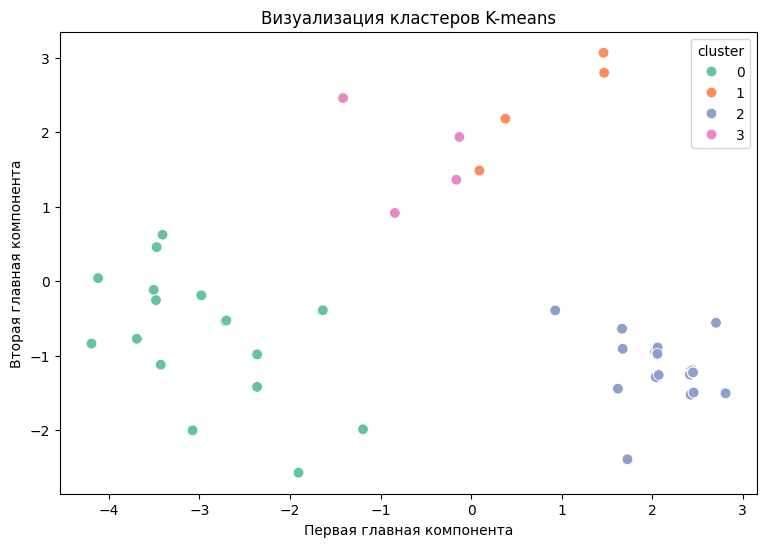

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['cluster'],
    palette='Set2',
    s=60
)

plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Визуализация кластеров K-means')
plt.show()

In [ ]:
print(
    'Доля объяснённой дисперсии:',
    pca.explained_variance_ratio_.sum()
)

Доля объяснённой дисперсии: 0.7798351988951506


Первые две главные компоненты объясняют около **77,98%** общей дисперсии исходных данных

Следовательно, двумерная визуализация сохраняет значительную часть информации о различиях между покупателями. На графике наблюдается визуальное разделение четырёх групп

Однако оставшаяся часть дисперсии не отражается на графике, поэтому визуализация PCA используется как дополнительный инструмент анализа, а не как самостоятельное доказательство качества кластеризации

**Анализ компактности кластеров**

Для дополнительной оценки полученных групп рассчитаем евклидово расстояние от каждого покупателя до центроида его кластера

Для каждой группы определим среднее расстояние, максимальное расстояние и стандартное отклонение расстояний

Эти показатели позволяют сравнить степень разброса объектов относительно центров кластеров. Чем меньше среднее расстояние, тем компактнее группа по данному критерию

In [ ]:
centers = kmeans.cluster_centers_

distances = np.linalg.norm(
    X - centers[df['cluster'].to_numpy()],
    axis=1
)

df['distance_to_center'] = distances

cluster_distances = df.groupby('cluster')['distance_to_center'].agg(
    ['mean', 'max', 'std']
)

cluster_distances.round(3)

,mean,max,std
cluster,,,
0,1.385,2.855,0.568
1,0.830,1.610,0.444
2,0.849,2.257,0.462
3,0.375,2.063,0.537


Анализ расстояний до центроидов показал, что наиболее компактным по среднему расстоянию является кластер 3 (0,375), соответствующий мотивам концентрации и отвлечения

Наибольшее среднее расстояние наблюдается в кластере 0 (1,385), что свидетельствует о более выраженной неоднородности ответов покупателей с лечебным мотивом

Кластеры 1 и 2 имеют близкие средние расстояния до центроидов — 0,830 и 0,849 соответственно

Таким образом, полученные группы различаются не только преобладающими мотивами потребления, но и степенью внутренней компактности

**Общий вывод**

В ходе лабораторной работы была проведена сегментация 338 потребителей леденцов методом K-means на основе 11 признаков, отражающих мотивы потребления

Для определения количества кластеров использовались метод локтя и три метрики качества: коэффициент силуэта, индексы Дэвиса–Болдуина и Калинского–Харабаша. По совокупности результатов было выбрано разбиение на четыре кластера

Анализ средних значений признаков позволил выделить четыре потребительских сегмента: ориентированные на лечебные свойства, сладкий вкус, свежесть и уверенность, а также концентрацию и отвлечение

Дополнительная визуализация методом PCA и анализ расстояний до центроидов позволили исследовать пространственное расположение и компактность полученных групп

Практическая значимость исследования заключается в возможности разработки отдельных маркетинговых предложений для каждого сегмента: акцентирования лечебных характеристик, вкусовых качеств, ощущения свежести или функциональных мотивов потребления

Таким образом, метод K-means позволил получить интерпретируемую сегментацию покупателей, которая может использоваться как основа для дальнейшего маркетингового анализа